# Обучение модели: от исходных категорий до метрик и разбора ошибок

**Проект:** повторная госпитализация пациентов с диабетом. **Авторы:** Кайырбек Женисов и Бекарыс Ережеп.

Это исполняемый учебный эксперимент: ячейки **обучают модели заново**, а не только читают старые метрики.
Читать и запускать сверху вниз: Jupyter / VS Code → **Restart Kernel and Run All**.
Зависимости: `python -m pip install -r requirements.txt` из корня репозитория.

Путь работы:
1. Загрузить источник, определить целевую переменную и популяцию.
2. Разделить **пациентов**, а не отдельные визиты, на четыре части.
3. Понять признаки, пропуски, категории, one-hot и стандартизацию.
4. Обучить Dummy, Logistic Regression и LightGBM.
5. Найти гиперпараметры на групповой CV и проверить, стало ли лучше.
6. Откалибровать вероятности и выбрать порог на отдельных данных.
7. Зафиксировать модель, рассчитать метрики на test и разобрать ошибки.

Новый эксперимент сохраняется в `reports/model_training_detailed/` и
`artifacts/notebook_training/`; действующая модель сайта не перезаписывается.
Обучение занимает несколько минут или дольше в зависимости от компьютера.
Готовые outputs позволяют изучить этот файл без повторного обучения.

## 1. Настройки и воспроизводимость

По умолчанию используются **все данные**, три групповых CV-фолда, три набора параметров
логистической регрессии и четыре — LightGBM. `EXTENDED_SEARCH=True` увеличивает
бюджет до 8/12 кандидатов, но не гарантирует улучшения. Случайность фиксируем.

Это отдельный учебный запуск. Его показатели могут отличаться от прежних отчётов проекта.
Test из этого набора уже просматривался в предыдущих экспериментах: внутри текущего
запуска он не используется для выбора решений, но полностью новое независимое
подтверждение потребовало бы других пациентов / нового источника данных.

In [1]:
from pathlib import Path
import sys, json, time, platform, importlib.metadata
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'src' / 'features.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, confusion_matrix,
    classification_report, precision_recall_curve, roc_curve, brier_score_loss)
from threadpoolctl import threadpool_limits
import joblib

from src.config import SEED, TARGET, NUM_COLS, CODE_COLS, DIAG_COLS, ARTIFACTS, REPORTS
from src.data import load_data, make_cohort, patient_split
from src.features import (FeatureBuilder, INPUT_COLS, MODEL_NUM_COLS,
                          MODEL_CAT_COLS, build_pipeline, icd9_group)
from src.modeling import model_candidates, choose_threshold, evaluate, group_bootstrap
get_ipython().run_line_magic('matplotlib', 'inline')

EXTENDED_SEARCH = False
N_ITER = {'LogisticRegression': 8 if EXTENDED_SEARCH else 3,
          'LightGBM': 12 if EXTENDED_SEARCH else 4}
CV_SPLITS = 3
BOOTSTRAP_REPEATS = 200
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT = REPORTS / 'model_training_detailed'
MODEL_OUT = ARTIFACTS / 'notebook_training'
OUT.mkdir(parents=True, exist_ok=True)
MODEL_OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

def show_plot(name):
    """Сохранить текущий график и показать его непосредственно в ноутбуке."""
    plt.tight_layout()
    plt.savefig(OUT / (name + '.png'), dpi=130, bbox_inches='tight')
    plt.show()
    plt.close()

versions = {name: importlib.metadata.version(name) for name in
            ['pandas', 'numpy', 'scikit-learn', 'lightgbm', 'joblib']}
display(pd.Series({'python': platform.python_version(), **versions}, name='version'))
print('Бюджет поиска:', N_ITER, '; исходные данные не уменьшаются.')

python          3.11.9
pandas           3.0.0
numpy            2.4.1
scikit-learn     1.9.1
lightgbm         4.7.0
joblib           1.6.0
Name: version, dtype: str

Бюджет поиска: {'LogisticRegression': 3, 'LightGBM': 4} ; исходные данные не уменьшаются.


## 2. Данные, цель и момент предсказания

Одна строка — госпитализация. `readmitted`: `<30` → 1, `NO` и `>30` → 0.
Это **зарегистрированный** возврат в системе, а не все возможные обращения пациента.
Прогноз делается при выписке: число процедур и исход выписки в этот момент уже известны.
Для прогноза при поступлении набор признаков пришлось бы изменить.

Знак `?` означает пропуск. Категория `None` в лабораторных результатах означает,
что исследование не выполнялось, поэтому её сохраняем. До разбиения исключаем
смерть и хоспис. Неизвестный пол сохраняется и затем обрабатывается как пропуск.
Повторные госпитализации одного пациента не удаляем как дубликаты.

In [2]:
raw, mappings, source_info = load_data()
cohort, flow = make_cohort(raw)
display(pd.Series(flow, name='число записей'))
display(raw.head(3))
assert raw.encounter_id.is_unique
assert cohort[TARGET].isin([0, 1]).all()
target_table = cohort[TARGET].value_counts().sort_index().rename('rows').to_frame()
target_table['percent'] = target_table.rows / len(cohort) * 100
display(target_table)
print('SHA256 исходного архива:', source_info['archive_sha256'])

raw_encounters        101766
raw_patients           71518
death_encounters        1652
hospice_encounters       771
cohort_encounters      99343
cohort_patients        69990
cohort_positive        11314
Name: число записей, dtype: int64

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,...,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),<NA>,6,25,1,1,<NA>,Pediatrics-Endocrinology,41,0,1,...,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),<NA>,1,1,7,3,<NA>,<NA>,59,0,18,...,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),<NA>,1,1,7,2,<NA>,<NA>,11,5,13,...,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO


,rows,percent
readmitted_30d,,
0,88029,88.611175
1,11314,11.388825


SHA256 исходного архива: f82ac129da2ddd2299391ff6fbae3a6a58b3edcf59ac9d7bd480c00fe453112a


## 3. Защита от утечки: четыре независимые группы пациентов

| Часть | Доля пациентов примерно | Для чего используется |
|---|---:|---|
| fit | 60% | обучение, импутация, стандартизация, словарь категорий, CV и гиперпараметры |
| calibration | 10% | обучение поправки к вероятностям уже обученной модели |
| validation | 10% | сравнение вариантов, выбор модели и порога |
| test | 20% | итоговая проверка зафиксированных решений |

Доли строк могут отличаться от долей пациентов: у людей разное число визитов.
Один `patient_nbr` не может находиться в двух частях. Перемешивание отдельных
строк этого не обеспечивает. Пока не доходим до итоговой оценки, признаки и
ответы test не используем для обучения или выбора решений.

In [3]:
parts = patient_split(cohort)
fit, calibration, validation, test = [parts[name] for name in
                                    ['fit', 'calibration', 'validation', 'test']]
split_summary = pd.DataFrame([
    {'split': name, 'rows': len(frame), 'patients': frame.patient_nbr.nunique(),
     'positive_rate': frame[TARGET].mean()}
    for name, frame in parts.items()])
display(split_summary)
overlap = pd.DataFrame({a: {b: len(set(fa.patient_nbr) & set(fb.patient_nbr))
                           for b, fb in parts.items()} for a, fa in parts.items()})
display(overlap)
for a, fa in parts.items():
    for b, fb in parts.items():
        if a != b:
            assert set(fa.patient_nbr).isdisjoint(fb.patient_nbr)
X_fit, y_fit = fit[INPUT_COLS], fit[TARGET]
X_cal, y_cal = calibration[INPUT_COLS], calibration[TARGET]
X_val, y_val = validation[INPUT_COLS], validation[TARGET]
assert not {'encounter_id', 'patient_nbr', 'readmitted', TARGET} & set(INPUT_COLS)
split_summary.to_csv(OUT / 'splits.csv', index=False)

,split,rows,patients,positive_rate
0,fit,59735,41994,0.114757
1,calibration,9898,6999,0.119115
2,validation,9908,6999,0.107388
3,test,19802,13998,0.111908


,fit,calibration,validation,test
fit,41994,0,0,0
calibration,0,6999,0,0
validation,0,0,6999,0
test,0,0,0,13998


## 4. Какие столбцы числовые, а какие — категории

Числовые признаки описывают количество: дни, процедуры, предыдущие обращения.
Коды `admission_type_id`, `discharge_disposition_id`, `admission_source_id` —
**названия категорий**, хотя выглядят как числа: код 4 не означает «вдвое больше» кода 2.
Возраст в источнике — интервал, его оставляем категорией. Номера пациентов и
госпитализаций, исходный ответ и бинарная цель запрещены как входы модели.

Категориальный dtype Pandas помогает хранить строки компактнее, но сам по себе
не превращает их в пригодные для логистической регрессии признаки.
Для модели ниже применяется OneHotEncoder, а не произвольные номера категорий.

In [4]:
column_roles = pd.DataFrame([
    {'column': col, 'role': 'число' if col in NUM_COLS else 'категория / исходный код',
     'dtype': str(X_fit[col].dtype), 'unique_fit': X_fit[col].nunique(),
     'missing_fit_pct': X_fit[col].isna().mean()*100}
    for col in INPUT_COLS])
display(column_roles)
category_demo = X_fit['medical_specialty'].astype('category')
display(pd.Series({'строки, МБ': X_fit.medical_specialty.memory_usage(deep=True)/1024**2,
                   'category, МБ': category_demo.memory_usage(deep=True)/1024**2}))

,column,role,dtype,unique_fit,missing_fit_pct
0,time_in_hospital,число,int64,14,0.000000
1,num_lab_procedures,число,int64,115,0.000000
2,num_procedures,число,int64,7,0.000000
3,num_medications,число,int64,74,0.000000
4,number_outpatient,число,int64,34,0.000000
5,number_emergency,число,int64,27,0.000000
6,number_inpatient,число,int64,17,0.000000
7,number_diagnoses,число,int64,16,0.000000
8,race,категория / исходный код,string,5,2.268352
9,gender,категория / исходный код,string,3,0.000000


строки, МБ      1.382428
category, МБ    0.514347
dtype: float64

## 5. Feature engineering: укрупнение диагнозов и дополнительные признаки

Сотни ICD-9 кодов переводим в укрупнённые группы: например, `250.83` → Diabetes,
`428` → Circulatory. Коды V/E → Other; отсутствующий диагноз → Missing.
Число назначенных препаратов и изменений дозы, наличие анализов/записи веса,
сумма предыдущих обращений — детерминированные признаки одной госпитализации.

Не добавляем общее число визитов пациента за весь источник: так можно использовать
его будущие посещения. `FeatureBuilder` одинаково применяется в обучении и прогнозе.
Два фиксированно исключённых лекарственных столбца постоянны в источнике;
остальные редкие категории объединяются **по fit конкретного CV-фолда**.

In [5]:
examples = ['250.83', '428', '486', '820', 'V57', None]
display(pd.DataFrame({'ICD-9': examples, 'group': [icd9_group(value) for value in examples]}))
feature_builder = FeatureBuilder()
engineered = feature_builder.fit_transform(X_fit)
display(pd.concat([X_fit[['diag_1', 'number_outpatient', 'number_emergency', 'number_inpatient']].head(),
                   engineered[['diag_1_group', 'prior_visits_total', 'n_diabetes_drugs',
                               'n_dose_changes', 'A1C_measured']].head()], axis=1))
display(pd.Series({'числовых признаков после FeatureBuilder': len(MODEL_NUM_COLS),
                   'категориальных': len(MODEL_CAT_COLS)}))

,ICD-9,group
0,250.83,Diabetes
1,428,Circulatory
2,486,Respiratory
3,820,Injury
4,V57,Other
5,NaN,Missing


,diag_1,number_outpatient,number_emergency,number_inpatient,diag_1_group,prior_visits_total,n_diabetes_drugs,n_dose_changes,A1C_measured
1,276,0,0,0,Other,0.0,1.0,1.0,0.0
4,197,0,0,0,Neoplasms,0.0,2.0,0.0,0.0
5,414,0,0,0,Circulatory,0.0,1.0,0.0,0.0
7,428,0,0,0,Circulatory,0.0,1.0,0.0,0.0
8,398,0,0,0,Circulatory,0.0,2.0,0.0,0.0


числовых признаков после FeatureBuilder    14
категориальных                             36
dtype: int64

## 6. Пропуски и стандартизация чисел — показываем реальные преобразования

Для чисел: пропуск заменяется медианой, затем `z = (x - mean_fit) / std_fit`.
Среднее преобразованной обучающей части близко к 0, стандартное отклонение — к 1
для непостоянных столбцов (`ddof=0`). При прогнозе используется **та же** медиана,
среднее и масштаб. На validation/test ничего заново не вычисляем.

Логистической регрессии стандартизация помогает сопоставлять масштабы признаков.
Деревьям она обычно не нужна; здесь для совместимости с проектом используется
единый Pipeline. Демо ниже обучено только на fit. В реальной CV эти шаги заново
обучаются **внутри каждого фолда**, а не до разбиения на CV.
[Pipeline и ColumnTransformer — документация](https://scikit-learn.org/stable/modules/compose.html).

In [6]:
numeric_demo = Pipeline([
    ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('scale', StandardScaler())])
scaled_fit = numeric_demo.fit_transform(engineered[MODEL_NUM_COLS])
numeric_audit = pd.DataFrame({
    'feature': MODEL_NUM_COLS,
    'median_fit': numeric_demo['impute'].statistics_,
    'mean_before': engineered[MODEL_NUM_COLS].mean().to_numpy(),
    'mean_after': scaled_fit.mean(axis=0),
    'std_after': scaled_fit.std(axis=0)})
display(numeric_audit.round(6))
display(pd.DataFrame(scaled_fit[:5, :8], columns=MODEL_NUM_COLS[:8]))
assert np.isfinite(scaled_fit).all()

,feature,median_fit,mean_before,mean_after,std_after
0,time_in_hospital,4.0,4.370018,0.0,1.0
1,num_lab_procedures,44.0,42.906169,-0.0,1.0
2,num_procedures,1.0,1.331799,-0.0,1.0
3,num_medications,15.0,15.971725,-0.0,1.0
4,number_outpatient,0.0,0.360308,-0.0,1.0
5,number_emergency,0.0,0.204537,-0.0,1.0
6,number_inpatient,0.0,0.631556,-0.0,1.0
7,number_diagnoses,8.0,7.393722,0.0,1.0
8,n_diabetes_drugs,1.0,1.193103,0.0,1.0
9,n_dose_changes,0.0,0.286415,-0.0,1.0


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
0,-0.463814,0.822443,-0.783267,0.249543,-0.297898,-0.202779,-0.509338,0.825408
1,-1.140906,0.413619,-0.783267,-0.980778,-0.297898,-0.202779,-0.509338,-1.230047
2,-0.463814,-0.608441,2.745495,0.003479,-0.297898,-0.202779,-0.509338,0.825408
3,0.213278,1.537884,-0.783267,-0.488650,-0.297898,-0.202779,-0.509338,0.311544
4,2.921647,1.282370,0.392987,1.479864,-0.297898,-0.202779,-0.509338,0.311544


## 7. Категории: заполнение пропусков, редкие значения и one-hot

Для категории пропуск становится `Missing`, а OneHotEncoder создаёт бинарные
индикаторы. Например, одно поле «инсулин» превращается в отдельные признаки
для No / Steady / Up / Down. В одном поле действует только один индикатор.

`min_frequency=30` объединяет редкие значения в группу. Неизвестная категория при
прогнозе попадает в эту группу, если она есть; иначе кодируется нулями. Это не
ошибка и не обучение на новых данных. Не кодируем классы как 0/1/2/3 с выдуманным
порядком. Словарь one-hot определяется только обучающими строками.

In [7]:
categorical_demo = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='Missing', keep_empty_features=True)),
    ('encode', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30,
                             sparse_output=True, dtype=np.float32))])
encoded_fit = categorical_demo.fit_transform(engineered[MODEL_CAT_COLS])
encoder = categorical_demo['encode']
encoded_names = encoder.get_feature_names_out(MODEL_CAT_COLS)
display(pd.DataFrame({'column': MODEL_CAT_COLS,
                     'categories_seen_fit': [len(values) for values in encoder.categories_],
                     'rare_categories': [0 if values is None else len(values)
                                        for values in encoder.infrequent_categories_]}))
print('Форма one-hot матрицы:', encoded_fit.shape, '; ненулевых элементов:', encoded_fit.nnz)
print('Не превращаем всю разреженную матрицу в плотную: показываем только маленький фрагмент.')
display(pd.DataFrame(encoded_fit[:5, :12].toarray(), columns=encoded_names[:12]))
unseen_example = engineered[MODEL_CAT_COLS].head(1).copy()
unseen_example['medical_specialty'] = 'PreviouslyUnseenSpecialty'
assert categorical_demo.transform(unseen_example).shape[1] == encoded_fit.shape[1]

,column,categories_seen_fit,rare_categories
0,race,6,0
1,gender,3,1
2,age,10,0
3,admission_type_id,6,2
4,discharge_disposition_id,20,7
5,admission_source_id,15,7
6,payer_code,17,0
7,medical_specialty,71,36
8,max_glu_serum,4,0
9,A1Cresult,4,0


Форма one-hot матрицы: (59735, 203) ; ненулевых элементов: 2150460
Не превращаем всю разреженную матрицу в плотную: показываем только маленький фрагмент.


,race_AfricanAmerican,race_Asian,race_Caucasian,race_Hispanic,race_Missing,race_Other,gender_Female,gender_Male,gender_infrequent_sklearn,age_[0-10),age_[10-20),age_[20-30)
0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## 8. Итоговый Pipeline и групповая кросс-валидация

Единая цепочка: **FeatureBuilder → ColumnTransformer → модель**.
ColumnTransformer параллельно обрабатывает числовые и категориальные столбцы.
Каждый кандидат гиперпараметров проверяется на одинаковых трёх CV-фолдах внутри fit.
Внутри фолда медианы, стандартизация и словарь one-hot обучаются на train-фрагменте,
а затем применяются к отложенным пациентам этого фолда.

StratifiedGroupKFold сохраняет группы пациентов и старается сбалансировать классы;
идеально одинаковые доли редкого класса не гарантируются.
[Описание метода](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).

In [8]:
cv = StratifiedGroupKFold(n_splits=CV_SPLITS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_fit, y_fit, groups=fit.patient_nbr))
fold_audit = []
for number, (train_idx, holdout_idx) in enumerate(folds, 1):
    common = set(fit.iloc[train_idx].patient_nbr) & set(fit.iloc[holdout_idx].patient_nbr)
    assert not common
    fold_audit.append({'fold': number, 'train_rows': len(train_idx), 'holdout_rows': len(holdout_idx),
                       'train_positive_rate': y_fit.iloc[train_idx].mean(),
                       'holdout_positive_rate': y_fit.iloc[holdout_idx].mean(),
                       'patient_overlap': len(common)})
display(pd.DataFrame(fold_audit))
candidate_definitions = model_candidates(quick=False)
display(build_pipeline(candidate_definitions['LogisticRegression'][0]))

,fold,train_rows,holdout_rows,train_positive_rate,holdout_positive_rate,patient_overlap
0,1,39823,19912,0.114758,0.114755,0
1,2,39825,19910,0.114777,0.114716,0
2,3,39822,19913,0.114736,0.114799,0


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",1.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclud

## 9. Что будем измерять и зачем нужен Dummy

| Метрика | Смысл | Направление |
|---|---|---|
| ROC-AUC | насколько хорошо модель ранжирует положительные и отрицательные случаи | больше лучше |
| Average precision (AP) | качество precision–recall при редком положительном классе | больше лучше |
| Recall | какую долю фактических возвратов обнаружили | больше, но вместе с precision |
| Precision | какая доля предупреждений оказалась правильной | больше, но вместе с recall |
| F1 | гармоническое среднее precision и recall | больше лучше при выбранном пороге |
| Brier / log-loss | ошибка вероятностей | меньше лучше |
| Accuracy | доля правильных классов | опасно использовать отдельно при дисбалансе |

Здесь TP — обнаруженный возврат, FP — ложное предупреждение, FN — пропущенный
возврат, TN — правильно определённое отсутствие возврата. Формулы:
**precision = TP / (TP + FP)**; **recall = TP / (TP + FN)**;
**F1 = 2 × precision × recall / (precision + recall)**.
Brier — среднее `(вероятность − фактический класс)²` по всем записям.

В этом ноутбуке PR-AUC означает **AP**, а не трапецеидальную площадь под PR-кривой.
AP оценивает ранжирование, а F1/precision/recall зависят от порога. Dummy выдаёт всем
долю положительного класса на fit. При пороге 0.5 он обычно никого не предупреждает:
accuracy высокая, recall равен нулю. «Предупреждать всех» даёт recall=1, но низкий precision.
Оба примера показывают, почему одной метрики недостаточно.
[Определение AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

In [9]:
dummy = build_pipeline(DummyClassifier(strategy='prior')).fit(X_fit, y_fit)
dummy_val = dummy.predict_proba(X_val)[:, 1]
display(pd.DataFrame([
    {'policy': 'Dummy, порог 0.5', **evaluate(y_val, dummy_val, 0.5)},
    {'policy': 'Dummy, предупреждать всех', **evaluate(y_val, dummy_val, 0.0)}
]).round(4))
print('AP случайного постоянного ранжирования на validation ≈ доле единиц:', y_val.mean())

,policy,roc_auc,pr_auc_ap,f1,precision,recall,accuracy,brier,log_loss,ece_10bins,threshold
0,"Dummy, порог 0.5",0.5,0.1074,0.0000,0.0000,0.0,0.8926,0.0959,0.3413,0.0074,0.5
1,"Dummy, предупреждать всех",0.5,0.1074,0.1939,0.1074,1.0,0.1074,0.0959,0.3413,0.0074,0.0


AP случайного постоянного ранжирования на validation ≈ доле единиц: 0.10738796931772306


## 10. Начальные модели — точка отсчёта перед улучшениями

Logistic Regression — понятная линейная модель; LightGBM — ансамбль деревьев,
который может учитывать нелинейности и взаимодействия признаков. Здесь обе
модели сначала обучаются с начальными параметрами. Сохраняем validation-метрики,
чтобы потом сравнить улучшения с этой точкой, а не только между разными алгоритмами.

В проекте есть также Random Forest. В этом разборе оставляем две разные обучаемые
модели и baseline: это сокращает время Run All без исключения данных из обучения.

In [10]:
fitted = {'Dummy': dummy}
initial_rows, fit_times = [], {}
for family in ['LogisticRegression', 'LightGBM']:
    print('Обучение начальной модели:', family, flush=True)
    estimator = clone(candidate_definitions[family][0])
    pipeline = build_pipeline(estimator)
    started = time.perf_counter()
    with threadpool_limits(limits=1, user_api='blas'):
        pipeline.fit(X_fit, y_fit)
    label = family + ' / initial'
    fit_times[label] = time.perf_counter()-started
    fitted[label] = pipeline
    p = pipeline.predict_proba(X_val)[:, 1]
    initial_rows.append({'model': label, **evaluate(y_val, p, 0.5), 'fit_seconds': fit_times[label]})
initial_metrics = pd.DataFrame(initial_rows)
display(initial_metrics.round(4))

Обучение начальной модели: LogisticRegression


Обучение начальной модели: LightGBM


,model,roc_auc,pr_auc_ap,f1,precision,recall,accuracy,brier,log_loss,ece_10bins,threshold,fit_seconds
0,LogisticRegression / initial,0.6574,0.2016,0.0328,0.5143,0.0169,0.8927,0.0925,0.3260,0.0078,0.5,17.8469
1,LightGBM / initial,0.6632,0.2184,0.0328,0.5625,0.0169,0.8930,0.0915,0.3226,0.0063,0.5,11.6504


## 11. Что такое гиперпараметры и что ищет RandomizedSearchCV

Параметры модели (например, коэффициенты регрессии) находятся при `fit`.
**Гиперпараметры** задают способ обучения и выбираются снаружи:

- LR: `C` — обратная сила регуляризации; `class_weight` — веса ошибок классов.
- LightGBM: число деревьев, learning rate, сложность дерева (`num_leaves`),
  минимум наблюдений в листе, регуляризация, доли строк/признаков, вес единиц.

Сравниваем кандидатов по **среднему AP на групповой CV**, не по test и не по accuracy.
`model__` в имени адресует шаг `model` внутри Pipeline. Для каждого кандидата
показываем среднее, разброс по фолдам и время. Малый бюджет — это выбор нескольких
вариантов из пространства, а не доказательство найденного глобального оптимума.
Повышенный вес редкого класса может увеличить recall и ухудшить вероятности.
SMOTE и другие способы oversampling здесь не применяются.

In [11]:
search_spaces = []
for family in ['LogisticRegression', 'LightGBM']:
    _, grid, _ = candidate_definitions[family]
    for name, values in grid.items():
        search_spaces.append({'family': family, 'hyperparameter': name, 'values': str(values)})
display(pd.DataFrame(search_spaces))
searches, search_tables = {}, []
for family in ['LogisticRegression', 'LightGBM']:
    estimator, grid, _ = candidate_definitions[family]
    search = RandomizedSearchCV(
        build_pipeline(clone(estimator)), param_distributions=grid,
        n_iter=N_ITER[family], scoring={'ap': 'average_precision', 'roc_auc': 'roc_auc'},
        refit='ap', cv=folds, random_state=SEED, n_jobs=1, error_score='raise',
        return_train_score=True, verbose=1)
    print(f'Подбор {family}: {N_ITER[family]} кандидатов × {CV_SPLITS} фолда', flush=True)
    started = time.perf_counter()
    with threadpool_limits(limits=1, user_api='blas'):
        search.fit(X_fit, y_fit)
    label = family + ' / tuned'
    fit_times[label] = time.perf_counter()-started
    searches[family] = search
    fitted[label] = search.best_estimator_
    table = pd.DataFrame(search.cv_results_)
    table['family'] = family
    table['ap_train_minus_cv'] = table.mean_train_ap - table.mean_test_ap
    search_tables.append(table)
    display(table[['params', 'mean_train_ap', 'mean_test_ap', 'std_test_ap',
                   'mean_test_roc_auc', 'ap_train_minus_cv', 'mean_fit_time',
                   'rank_test_ap']].sort_values('rank_test_ap'))
    print('Лучшие гиперпараметры:', search.best_params_)
    print('Лучший CV AP:', round(search.best_score_, 5))
    table.to_csv(OUT / ('cv_' + family + '.csv'), index=False)

,family,hyperparameter,values
0,LogisticRegression,model__C,"[0.01, 0.1, 1.0, 10.0]"
1,LogisticRegression,model__class_weight,"[None, 'balanced']"
2,LightGBM,model__n_estimators,"[180, 350, 550]"
3,LightGBM,model__learning_rate,"[0.03, 0.06]"
4,LightGBM,model__num_leaves,"[15, 31]"
5,LightGBM,model__min_child_samples,"[40, 100]"
6,LightGBM,model__reg_lambda,"[1.0, 5.0]"
7,LightGBM,model__colsample_bytree,"[0.8, 1.0]"
8,LightGBM,model__subsample,"[0.8, 1.0]"
9,LightGBM,model__scale_pos_weight,"[1.0, 4.0]"


Подбор LogisticRegression: 3 кандидатов × 3 фолда


Fitting 3 folds for each of 3 candidates, totalling 9 fits


,params,mean_train_ap,mean_test_ap,std_test_ap,mean_test_roc_auc,ap_train_minus_cv,mean_fit_time,rank_test_ap
1,"{'model__class_weight': 'balanced', 'model__C'...",0.223929,0.213619,0.001668,0.658290,0.010310,16.630867,1
0,"{'model__class_weight': 'balanced', 'model__C'...",0.219222,0.213137,0.001745,0.661200,0.006086,8.992960,2
2,"{'model__class_weight': None, 'model__C': 0.01}",0.219411,0.212471,0.002212,0.660547,0.006940,7.436865,3


Лучшие гиперпараметры: {'model__class_weight': 'balanced', 'model__C': 1.0}
Лучший CV AP: 0.21362
Подбор LightGBM: 4 кандидатов × 3 фолда


Fitting 3 folds for each of 4 candidates, totalling 12 fits


,params,mean_train_ap,mean_test_ap,std_test_ap,mean_test_roc_auc,ap_train_minus_cv,mean_fit_time,rank_test_ap
0,"{'model__subsample': 0.8, 'model__scale_pos_we...",0.386118,0.229120,0.003226,0.672719,0.156998,12.087535,1
1,"{'model__subsample': 0.8, 'model__scale_pos_we...",0.313408,0.224810,0.002888,0.671671,0.088598,9.579619,2
2,"{'model__subsample': 1.0, 'model__scale_pos_we...",0.357299,0.222044,0.003082,0.667431,0.135254,5.925381,3
3,"{'model__subsample': 0.8, 'model__scale_pos_we...",0.645632,0.219509,0.002316,0.662863,0.426123,13.958599,4


Лучшие гиперпараметры: {'model__subsample': 0.8, 'model__scale_pos_weight': 1.0, 'model__reg_lambda': 5.0, 'model__num_leaves': 31, 'model__n_estimators': 350, 'model__min_child_samples': 100, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}
Лучший CV AP: 0.22912


## 12. Действительно ли подбор улучшил модель?

Сравниваем начальную и подобранную модели на одной validation с одинаковым
порогом 0.5. Метрики ранжирования от этого порога не зависят. Уменьшение разрыва
train–CV помогает замечать переобучение, но само по себе не гарантирует лучшего
результата на других данных. Изменение AP показываем со знаком: отрицательное
изменение нельзя называть улучшением. Test всё ещё не используется.

In [12]:
raw_validation_rows = []
for label, model in fitted.items():
    p = model.predict_proba(X_val)[:, 1]
    raw_validation_rows.append({'model': label, **evaluate(y_val, p, 0.5)})
raw_validation = pd.DataFrame(raw_validation_rows)
display(raw_validation.round(4))
improvements = []
for family in searches:
    base = raw_validation.set_index('model').loc[family + ' / initial']
    tuned = raw_validation.set_index('model').loc[family + ' / tuned']
    improvements.append({'family': family, 'AP_before': base.pr_auc_ap,
                         'AP_after': tuned.pr_auc_ap, 'delta_AP': tuned.pr_auc_ap-base.pr_auc_ap,
                         'ROC_before': base.roc_auc, 'ROC_after': tuned.roc_auc})
improvements = pd.DataFrame(improvements)
display(improvements.round(5))
for row in improvements.itertuples():
    print(row.family, ':', 'AP вырос' if row.delta_AP > 0 else 'AP не вырос',
          f'({row.delta_AP:+.5f}); это результат данного бюджета и validation.')

,model,roc_auc,pr_auc_ap,f1,precision,recall,accuracy,brier,log_loss,ece_10bins,threshold
0,Dummy,0.5000,0.1074,0.0000,0.0000,0.0000,0.8926,0.0959,0.3413,0.0074,0.5
1,LogisticRegression / initial,0.6574,0.2016,0.0328,0.5143,0.0169,0.8927,0.0925,0.3260,0.0078,0.5
2,LightGBM / initial,0.6632,0.2184,0.0328,0.5625,0.0169,0.8930,0.0915,0.3226,0.0063,0.5
3,LogisticRegression / tuned,0.6593,0.2023,0.2578,0.1701,0.5320,0.6711,0.2249,0.6458,0.3552,0.5
4,LightGBM / tuned,0.6679,0.2122,0.0221,0.5455,0.0113,0.8928,0.0918,0.3226,0.0064,0.5


,family,AP_before,AP_after,delta_AP,ROC_before,ROC_after
0,LogisticRegression,0.20162,0.20234,0.00073,0.65740,0.65926
1,LightGBM,0.21845,0.21224,-0.00621,0.66319,0.66793


LogisticRegression : AP вырос (+0.00073); это результат данного бюджета и validation.
LightGBM : AP не вырос (-0.00621); это результат данного бюджета и validation.


## 13. Калибровка: вероятность и правильный порядок случаев — разные задачи

AP/ROC-AUC оценивают ранжирование: у кого риск выше. Калибровка отвечает другому
вопросу: среди случаев с прогнозом около 20% действительно ли возвращается около 20%?
Обучаем sigmoid-поправку на **calibration**, замораживая уже обученный Pipeline.
Validation остаётся отдельной и используется только для сравнения результатов.

Монотонная sigmoid-поправка обычно сохраняет порядок и поэтому не обязана менять
AP/ROC-AUC. Brier и log-loss могут улучшиться или ухудшиться — это проверяем таблицей.
Точка на диагонали reliability diagram соответствует совпадению средней вероятности
с частотой исхода в группе; малые группы дают нестабильные точки.
[Калибровка вероятностей](https://scikit-learn.org/stable/modules/calibration.html).

,model,Brier_before,Brier_after,AP_before,AP_after
0,Dummy,0.09591,0.09591,0.10739,0.10739
1,LogisticRegression / initial,0.09252,0.09252,0.20162,0.20162
2,LightGBM / initial,0.09155,0.09161,0.21845,0.21845
3,LogisticRegression / tuned,0.22494,0.09245,0.20234,0.20234
4,LightGBM / tuned,0.09180,0.09187,0.21224,0.21224


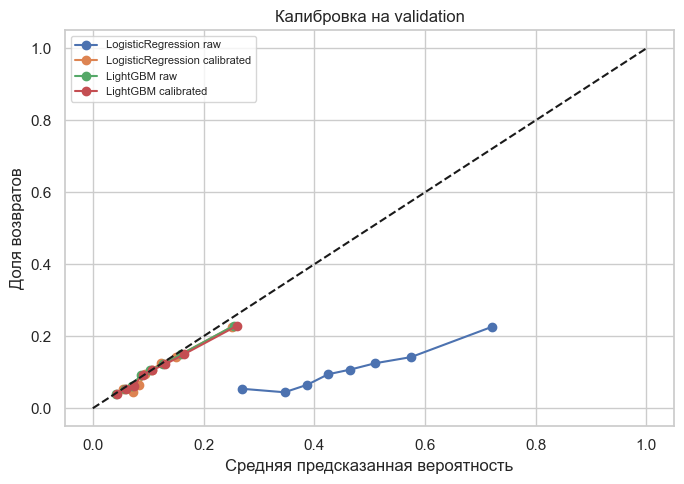

In [13]:
calibrated_models = {'Dummy': dummy}
calibration_rows, val_probabilities = [], {}
for label, model in fitted.items():
    if label == 'Dummy':
        calibrated = model
    else:
        calibrated = CalibratedClassifierCV(FrozenEstimator(model), method='sigmoid')
        calibrated.fit(X_cal, y_cal)
    calibrated_models[label] = calibrated
    before = model.predict_proba(X_val)[:, 1]
    after = calibrated.predict_proba(X_val)[:, 1]
    val_probabilities[label] = after
    calibration_rows.append({'model': label,
        'Brier_before': brier_score_loss(y_val, before),
        'Brier_after': brier_score_loss(y_val, after),
        'AP_before': average_precision_score(y_val, before),
        'AP_after': average_precision_score(y_val, after)})
calibration_table = pd.DataFrame(calibration_rows)
display(calibration_table.round(5))
plt.figure(figsize=(7, 5))
for label in searches:
    key = label + ' / tuned'
    for stage, probabilities in [('raw', fitted[key].predict_proba(X_val)[:, 1]),
                                  ('calibrated', val_probabilities[key])]:
        observed, predicted = calibration_curve(y_val, probabilities, n_bins=8, strategy='quantile')
        plt.plot(predicted, observed, marker='o', label=label + ' ' + stage)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('Средняя предсказанная вероятность'); plt.ylabel('Доля возвратов')
plt.title('Калибровка на validation'); plt.legend(fontsize=8)
show_plot('calibration_validation')

## 14. Выбор порога и лучшей модели — только на validation

Порог 0.5 не является универсальным. При редком классе и откалиброванных
вероятностях он может дать почти нулевой recall. Для каждой обучаемой модели
выбираем порог максимального F1 на validation. Dummy оставляем с порогом 0.5.
Лучшую модель выбираем по validation AP, при равенстве — по меньшему Brier.
Начальный вариант тоже может победить: подбор не должен принудительно вытеснять его.

Дополнительно показываем цену порога: число предупреждений на 100 случаев,
precision и recall. Можно выбрать иную политику, но **до итогового test**.
Здесь выбор F1 учебный: клинические стоимости ошибок и допустимая нагрузка не заданы.

,model,roc_auc,pr_auc_ap,f1,precision,recall,accuracy,brier,log_loss,ece_10bins,threshold
2,LightGBM / initial,0.66319,0.21845,0.26644,0.18099,0.50470,0.70155,0.09161,0.32284,0.01025,0.13091
4,LightGBM / tuned,0.66793,0.21224,0.27046,0.18290,0.51880,0.69943,0.09187,0.32286,0.00919,0.13167
3,LogisticRegression / tuned,0.65926,0.20234,0.26228,0.18162,0.47180,0.71498,0.09245,0.32606,0.01034,0.12779
1,LogisticRegression / initial,0.65740,0.20162,0.26069,0.19176,0.40695,0.75212,0.09252,0.32612,0.01080,0.13833
0,Dummy,0.50000,0.10739,0.00000,0.00000,0.00000,0.89261,0.09591,0.34129,0.00737,0.50000


Решение зафиксировано ДО test: LightGBM / initial ; порог: 0.13091470009185502


,threshold,precision,recall,f1,alerts_per_100
0,0.0500,0.1130,0.9727,0.2025,92.4203
1,0.1000,0.1503,0.6880,0.2468,49.1421
2,0.1309,0.1810,0.5047,0.2664,29.9455
3,0.1500,0.1916,0.3853,0.2559,21.5987
4,0.2000,0.2476,0.2199,0.2330,9.5377
5,0.5000,0.5625,0.0169,0.0328,0.3230


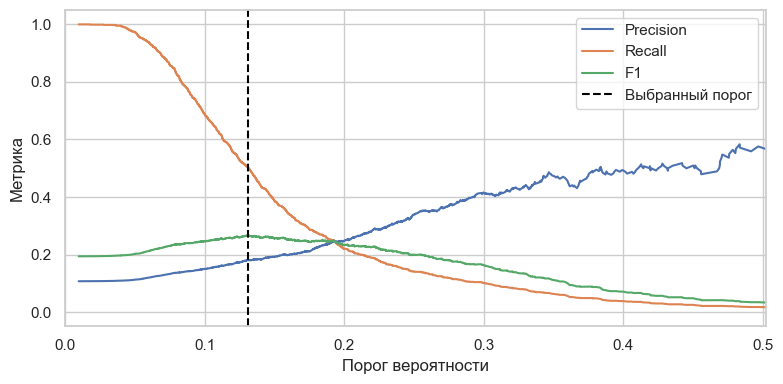

In [14]:
thresholds, validation_rows = {}, []
for label, probabilities in val_probabilities.items():
    threshold = 0.5 if label == 'Dummy' else choose_threshold(y_val, probabilities)
    thresholds[label] = threshold
    validation_rows.append({'model': label, **evaluate(y_val, probabilities, threshold)})
validation_metrics = pd.DataFrame(validation_rows)
display(validation_metrics.sort_values('pr_auc_ap', ascending=False).round(5))
winner = (validation_metrics.query("model != 'Dummy'")
          .sort_values(['pr_auc_ap', 'brier'], ascending=[False, True]).iloc[0]['model'])
chosen_threshold = thresholds[winner]
selected_model = calibrated_models[winner]
selection = {'run_id': RUN_ID, 'winner': winner, 'threshold': chosen_threshold,
             'criterion': 'validation AP, tie-break lower Brier',
             'test_not_used_for_selection': True, 'source_sha256': source_info['archive_sha256'],
             'search_budget': N_ITER, 'versions': versions}
(OUT / 'selection.json').write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('Решение зафиксировано ДО test:', winner, '; порог:', chosen_threshold)

p_val = val_probabilities[winner]
threshold_table = pd.DataFrame([
    {'threshold': value, **evaluate(y_val, p_val, value),
     'alerts_per_100': 100*np.mean(p_val >= value)}
    for value in sorted(set([0.05, 0.10, 0.15, 0.20, 0.50, chosen_threshold]))])
display(threshold_table[['threshold', 'precision', 'recall', 'f1', 'alerts_per_100']].round(4))
precision, recall, cutoffs = precision_recall_curve(y_val, p_val)
f1_values = 2*precision[:-1]*recall[:-1] / np.maximum(precision[:-1]+recall[:-1], 1e-15)
plt.figure(figsize=(8, 4))
for values, label in [(precision[:-1], 'Precision'), (recall[:-1], 'Recall'), (f1_values, 'F1')]:
    plt.plot(cutoffs, values, label=label)
plt.axvline(chosen_threshold, color='black', linestyle='--', label='Выбранный порог')
plt.xlabel('Порог вероятности'); plt.ylabel('Метрика'); plt.legend()
plt.xlim(0, min(0.8, float(np.quantile(p_val, .995)) + .05))
show_plot('threshold_validation')

## 15. Итоговая оценка на test

Теперь все Pipeline, калибраторы, модель-победитель и пороги уже зафиксированы.
Впервые в этом запуске получаем прогнозы test для сравнения фиксированных вариантов.
Не меняем победителя по этой таблице и не подбираем порог повторно.
Validation-метрики были использованы для выбора и потому оптимистичнее как основание
для заявления о качестве; test показывает перенос на отложенных пациентов этого набора.
Оценка относится к госпитализациям: пациенты с несколькими визитами имеют больший вес.

In [15]:
X_test, y_test = test[INPUT_COLS], test[TARGET]
test_rows, test_probabilities = [], {}
for label, model in calibrated_models.items():
    started = time.perf_counter()
    probabilities = model.predict_proba(X_test)[:, 1]
    elapsed = time.perf_counter()-started
    test_probabilities[label] = probabilities
    test_rows.append({'model': label, **evaluate(y_test, probabilities, thresholds[label]),
                      'selected_on_validation': label == winner,
                      'predict_ms_per_1000': elapsed/len(test)*1e6})
test_metrics = pd.DataFrame(test_rows)
display(test_metrics.round(5))
for filename, table in [('initial_validation', initial_metrics), ('tuning_changes', improvements),
                         ('calibration_validation', calibration_table), ('validation_metrics', validation_metrics),
                         ('thresholds_validation', threshold_table), ('test_metrics', test_metrics)]:
    table.to_csv(OUT / (filename + '.csv'), index=False)

,model,roc_auc,pr_auc_ap,f1,precision,recall,accuracy,brier,log_loss,ece_10bins,threshold,selected_on_validation,predict_ms_per_1000
0,Dummy,0.50000,0.11191,0.00000,0.00000,0.00000,0.88809,0.09939,0.35053,0.00285,0.50000,False,82.44165
1,LogisticRegression / initial,0.66708,0.22096,0.27792,0.20530,0.43005,0.74992,0.09511,0.33214,0.00677,0.13833,False,72.00131
2,LightGBM / initial,0.67006,0.23158,0.28318,0.19384,0.52527,0.70240,0.09436,0.32988,0.00629,0.13091,True,83.56154
3,LogisticRegression / tuned,0.66785,0.22042,0.27528,0.19146,0.48962,0.71149,0.09520,0.33237,0.00683,0.12779,False,81.98479
4,LightGBM / tuned,0.67365,0.23023,0.28325,0.19277,0.53384,0.69766,0.09437,0.32948,0.00655,0.13167,False,108.98520


## 16. ROC, precision–recall и матрица ошибок

ROC показывает компромисс между обнаруженными возвратами и ложноположительной
долей. PR-кривая при редком классе нагляднее показывает качество предупреждений;
горизонтальная линия — доля единиц test. Матрица ошибок использует **выбранный
ранее** порог: FN — пропущенный возврат, FP — лишнее предупреждение.

Полезно считать не только проценты: например, recall 50% означает, что половина
фактических возвратов осталась не обнаружена. Это не клинически валидированный инструмент.

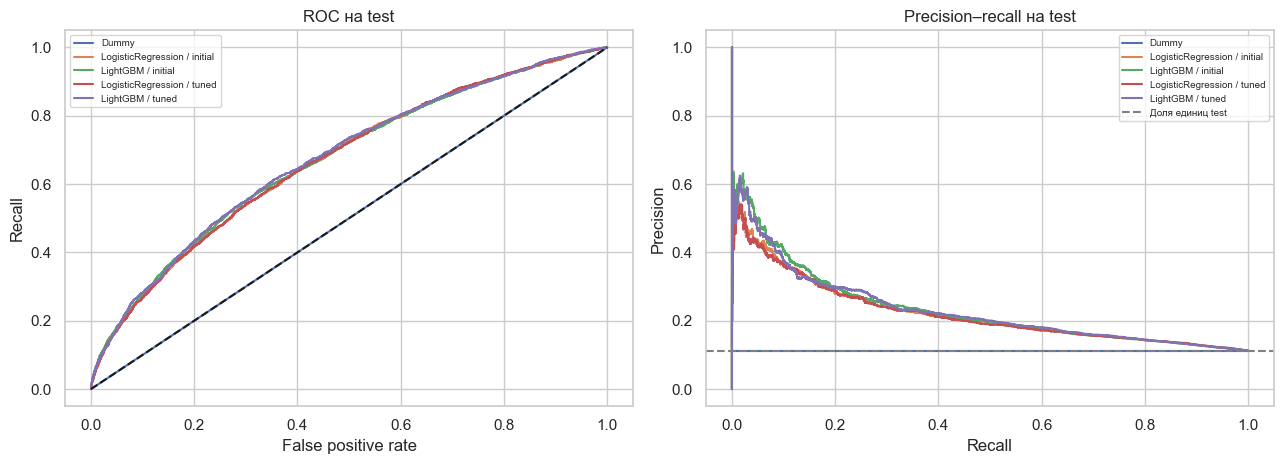

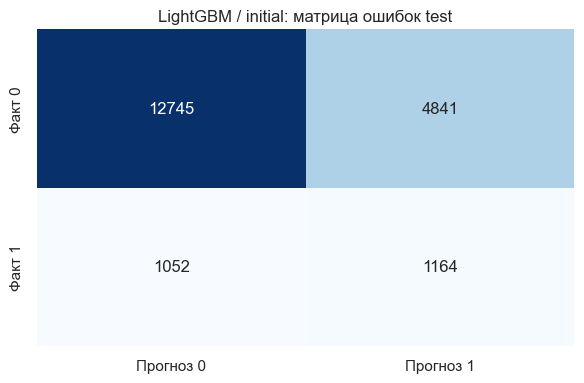

,precision,recall,f1-score,support
0,0.923752,0.724724,0.812223,17586.000000
1,0.193838,0.525271,0.283177,2216.000000
accuracy,0.702404,0.702404,0.702404,0.702404
macro avg,0.558795,0.624997,0.547700,19802.000000
weighted avg,0.842069,0.702404,0.753019,19802.000000


TN                       12745
FP                        4841
FN                        1052
TP                        1164
пропущено возвратов       1052
лишних предупреждений     4841
dtype: int64

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for label, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    axes[0].plot(fpr, tpr, label=label)
    axes[1].step(recall, precision, where='post', label=label)
axes[0].plot([0,1], [0,1], 'k--')
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', label='Доля единиц test')
axes[0].set(xlabel='False positive rate', ylabel='Recall', title='ROC на test')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–recall на test')
for ax in axes:
    ax.legend(fontsize=7)
show_plot('test_curves')

p_test = test_probabilities[winner]
predicted = (p_test >= chosen_threshold).astype(int)
matrix = confusion_matrix(y_test, predicted, labels=[0,1])
plt.figure(figsize=(6,4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Прогноз 0', 'Прогноз 1'], yticklabels=['Факт 0', 'Факт 1'])
plt.title(winner + ': матрица ошибок test')
show_plot('confusion_test')
display(pd.DataFrame(classification_report(y_test, predicted, output_dict=True, zero_division=0)).T)
tn, fp, fn, tp = matrix.ravel()
display(pd.Series({'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                   'пропущено возвратов': fn, 'лишних предупреждений': fp}))

## 17. Неопределённость: bootstrap по пациентам

Визиты одного пациента зависимы. Поэтому bootstrap перевыбирает **пациентов**,
а все их визиты получают общий вес. Показываем 95% percentile-интервалы ROC-AUC,
AP и F1 при фиксированной модели и пороге. Они не включают всю неопределённость
подбора гиперпараметров, не являются интервалами индивидуального риска и не
доказывают качество на другой больнице. 200 повторов — учебный компромисс;
для более стабильных границ увеличьте число повторов до нового итогового запуска.

In [17]:
intervals = group_bootstrap(y_test, p_test, test.patient_nbr,
                            chosen_threshold, n_bootstrap=BOOTSTRAP_REPEATS)
display(pd.Series(intervals, name='95% bootstrap').round(5))
(OUT / 'bootstrap_intervals.json').write_text(json.dumps(intervals, indent=2), encoding='utf-8')

roc_auc_ci_low       0.65563
roc_auc_ci_high      0.68209
pr_auc_ap_ci_low     0.21102
pr_auc_ap_ci_high    0.25106
f1_ci_low            0.26781
f1_ci_high           0.29759
Name: 95% bootstrap, dtype: float64

240

## 18. Почему модель предсказывает: permutation importance и коэффициенты

Перемешиваем один исходный признак на validation и смотрим, насколько падает AP.
Большое падение означает, что модель использовала информацию этого признака.
Используем исходные поля и весь Pipeline: зависимые производные признаки
пересчитываются после перемешивания. Часть validation берётся для экономии времени,
а не для обучения. Важности описательные, не причинные; коррелирующие поля могут
заменять друг друга. Отрицательная важность может возникнуть из-за шума.

Для LR дополнительно выводим коэффициенты уже преобразованных признаков.
Коэффициент числа относится к изменению на одно обучающее стандартное отклонение;
интерпретация категорий зависит от кодирования и регуляризации. Это не эффект лечения.

,feature,importance_mean,importance_std
13,discharge_disposition_id,0.072577,0.004427
6,number_inpatient,0.027037,0.006781
0,time_in_hospital,0.021234,0.000277
17,diag_1,0.017314,0.004012
16,medical_specialty,0.017105,0.009182
18,diag_2,0.015765,0.003274
3,num_medications,0.014598,0.004255
8,race,0.005705,0.002955
20,max_glu_serum,0.005215,0.001465
21,A1Cresult,0.004438,0.007207


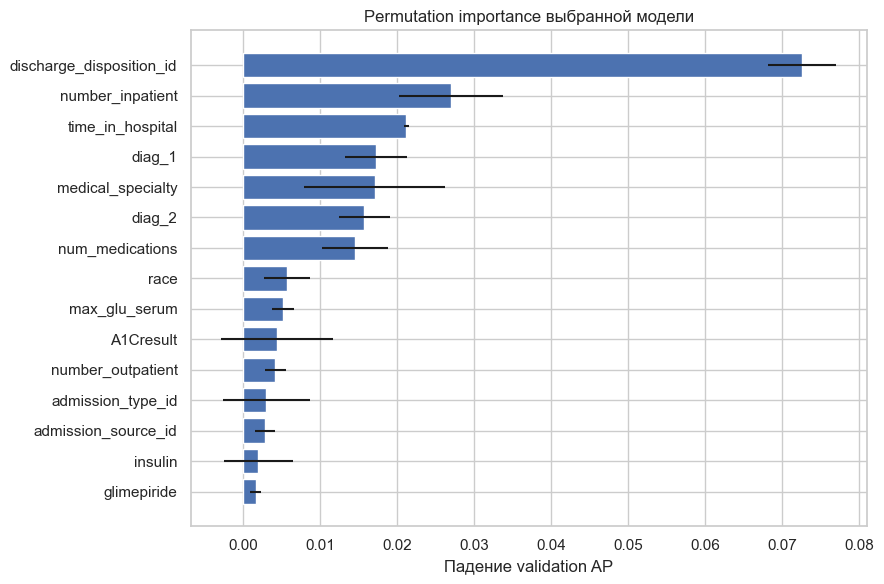

,feature,coefficient,abs_value
23,categorical__age_[0-10),-1.948691,1.948691
98,categorical__medical_specialty_Pediatrics-Endo...,-1.728525,1.728525
83,categorical__medical_specialty_Gynecology,-1.692090,1.692090
133,categorical__repaglinide_infrequent_sklearn,-1.499303,1.499303
95,categorical__medical_specialty_Otolaryngology,-1.374151,1.374151
84,categorical__medical_specialty_Hematology,1.191155,1.191155
42,categorical__discharge_disposition_id_23,-1.151417,1.151417
136,categorical__nateglinide_infrequent_sklearn,-1.127017,1.127017
166,categorical__acarbose_infrequent_sklearn,1.086534,1.086534
39,categorical__discharge_disposition_id_15,1.032173,1.032173


In [18]:
sample = validation.sample(n=min(1000, len(validation)), random_state=SEED)
importance = permutation_importance(selected_model, sample[INPUT_COLS], sample[TARGET],
                                    scoring='average_precision', n_repeats=3,
                                    random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'feature': INPUT_COLS,
    'importance_mean': importance.importances_mean,
    'importance_std': importance.importances_std}).sort_values('importance_mean', ascending=False)
display(importance_table.head(20))
view = importance_table.head(15).sort_values('importance_mean')
plt.figure(figsize=(9,6))
plt.barh(view.feature, view.importance_mean, xerr=view.importance_std)
plt.xlabel('Падение validation AP'); plt.title('Permutation importance выбранной модели')
show_plot('importance_validation')
importance_table.to_csv(OUT / 'permutation_importance.csv', index=False)

lr = fitted['LogisticRegression / tuned']
names = lr.named_steps['preprocess'].get_feature_names_out()
coefficient_table = pd.DataFrame({'feature': names, 'coefficient': lr.named_steps['model'].coef_[0]})
display(coefficient_table.assign(abs_value=lambda frame: frame.coefficient.abs())
        .sort_values('abs_value', ascending=False).head(20))

## 19. Разбор ошибок и возрастных / половых групп

Сравниваем FN, FP, TP и TN по прошлым госпитализациям и длительности пребывания.
Затем описательно проверяем группы: число записей/пациентов, частоту исхода,
precision и recall. Не объявляем малые группы надёжными выводами о различиях,
не делаем причинных или дискриминационных заключений. Этот анализ test не служит
новым подбором модели. Если после него изменить решение, понадобится другая
независимая проверка качества.

In [19]:
errors = test[['patient_nbr', 'age', 'gender', 'number_inpatient', 'time_in_hospital', TARGET]].copy()
errors['prediction'] = predicted
errors['probability'] = p_test
errors['error_type'] = np.select([
    errors[TARGET].eq(1) & errors.prediction.eq(0),
    errors[TARGET].eq(0) & errors.prediction.eq(1),
    errors[TARGET].eq(1) & errors.prediction.eq(1)], ['FN','FP','TP'], default='TN')
error_profiles = errors.groupby('error_type').agg(
    encounters=(TARGET, 'size'), patients=('patient_nbr','nunique'),
    mean_prior_inpatient=('number_inpatient','mean'),
    mean_stay=('time_in_hospital','mean'), mean_probability=('probability','mean'))
display(error_profiles.round(3))
subgroups = []
for field in ['age', 'gender']:
    for group, frame in errors.groupby(field, dropna=False):
        positives = int(frame[TARGET].sum())
        metrics = evaluate(frame[TARGET], frame.probability, chosen_threshold) if frame[TARGET].nunique()==2 else {}
        subgroups.append({'field': field, 'group': str(group), 'n': len(frame),
                          'patients': frame.patient_nbr.nunique(), 'positives': positives,
                          'precision': metrics.get('precision', np.nan),
                          'recall': metrics.get('recall', np.nan),
                          'note': 'малая группа: осторожная интерпретация' if len(frame)<200 or positives<20 else 'описательная оценка'})
subgroup_table = pd.DataFrame(subgroups)
display(subgroup_table)
error_profiles.to_csv(OUT / 'error_profiles.csv')
subgroup_table.to_csv(OUT / 'subgroups.csv', index=False)

,encounters,patients,mean_prior_inpatient,mean_stay,mean_probability
error_type,,,,,
FN,1052,1015,0.193,4.423,0.089
FP,4841,3498,1.599,5.179,0.193
TN,12745,11326,0.154,4.007,0.081
TP,1164,854,2.188,5.118,0.235


,field,group,n,patients,positives,precision,recall,note
0,age,[0-10),29,28,1,0.000000,0.000000,малая группа: осторожная интерпретация
1,age,[10-20),138,110,9,0.222222,0.444444,малая группа: осторожная интерпретация
2,age,[20-30),388,250,60,0.348387,0.900000,описательная оценка
3,age,[30-40),729,543,77,0.227027,0.545455,описательная оценка
4,age,[40-50),1909,1380,202,0.200000,0.460396,описательная оценка
5,age,[50-60),3469,2553,356,0.214103,0.469101,описательная оценка
6,age,[60-70),4266,3145,464,0.197520,0.480603,описательная оценка
7,age,[70-80),5040,3599,587,0.188732,0.570698,описательная оценка
8,age,[80-90),3287,2311,390,0.165138,0.553846,описательная оценка
9,age,[90-100),547,378,70,0.157895,0.428571,описательная оценка


## 20. Сохранение нового Pipeline и воспроизводимый прогноз

Сохраняется вся цепочка, включая обработку категорий, стандартизацию и калибратор.
При загрузке не нужно вручную повторять one-hot и подгонять новый scaler.
Проверяем совпадение вероятностей до и после сохранения на небольшом примере.
Файл отдельный: действующая `artifacts/best_model.joblib` не заменяется.
Версии Python/библиотек и SHA256 источника записаны в selection.json.
Не загружайте pickle/joblib из неизвестных источников.

In [20]:
model_path = MODEL_OUT / 'detailed_model.joblib'
bundle = {'model': selected_model, 'threshold': chosen_threshold, 'name': winner,
          'run_id': RUN_ID, 'input_columns': INPUT_COLS, 'selection': selection}
joblib.dump(bundle, model_path, compress=3)
loaded = joblib.load(model_path)
example = X_fit.head(3)
before = selected_model.predict_proba(example)[:,1]
after = loaded['model'].predict_proba(example)[:,1]
np.testing.assert_allclose(before, after, rtol=0, atol=1e-12)
display(pd.DataFrame({'probability': after, 'prediction': (after >= loaded['threshold']).astype(int)}))
print('Сохранён:', model_path.relative_to(ROOT))
print('Размер, МБ:', model_path.stat().st_size/1024**2)

,probability,prediction
0,0.093798,0
1,0.101486,0
2,0.077099,0


Сохранён: artifacts\notebook_training\detailed_model.joblib
Размер, МБ: 0.144500732421875


## 21. Итог: что получилось в этом запуске

Следующая ячейка собирает выводы из реально рассчитанных значений. Подбор,
калибровка и порог — разные этапы: улучшение одной метрики не означает улучшения
всех. Нет обещания ROC-AUC 0.9 или клинической пригодности на историческом наборе.

In [21]:
selected = test_metrics.set_index('model').loc[winner]
cal_row = calibration_table.set_index('model').loc[winner]
lines = [f'**Выбрана на validation:** {winner}. Порог: {chosen_threshold:.4f}.',
         f'**Test:** ROC-AUC {selected.roc_auc:.4f}; AP {selected.pr_auc_ap:.4f}; '
         f'precision {selected.precision:.4f}; recall {selected.recall:.4f}; F1 {selected.f1:.4f}.',
         f'**Вероятности на validation:** Brier до {cal_row.Brier_before:.5f}, после {cal_row.Brier_after:.5f}.',
         f'**Ошибки test:** пропущено {fn} возвратов; ложных предупреждений {fp}; обнаружено {tp}.']
for row in improvements.itertuples():
    lines.append(f'**{row.family}:** изменение validation AP после подбора {row.delta_AP:+.5f}.')
lines += ['**Ограничения:** историческая выборка, нет временной/межбольничной проверки; '
          'стоимость ошибок не задана; test ранее изучался в проекте. Учебный эксперимент, не медицинское решение.',
          '**Результаты:** reports/model_training_detailed/. Новая модель: artifacts/notebook_training/detailed_model.joblib.']
display(Markdown('\n\n'.join(lines)))
(OUT / 'summary.md').write_text('\n\n'.join(lines), encoding='utf-8')
assert all(set(a.patient_nbr).isdisjoint(b.patient_nbr)
           for name_a, a in parts.items() for name_b, b in parts.items() if name_a != name_b)
assert all(np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all() for p in test_probabilities.values())
print('Контроль пройден: группы независимы, вероятности корректны, сохранение воспроизводится.')

**Выбрана на validation:** LightGBM / initial. Порог: 0.1309.

**Test:** ROC-AUC 0.6701; AP 0.2316; precision 0.1938; recall 0.5253; F1 0.2832.

**Вероятности на validation:** Brier до 0.09155, после 0.09161.

**Ошибки test:** пропущено 1052 возвратов; ложных предупреждений 4841; обнаружено 1164.

**LogisticRegression:** изменение validation AP после подбора +0.00073.

**LightGBM:** изменение validation AP после подбора -0.00621.

**Ограничения:** историческая выборка, нет временной/межбольничной проверки; стоимость ошибок не задана; test ранее изучался в проекте. Учебный эксперимент, не медицинское решение.

**Результаты:** reports/model_training_detailed/. Новая модель: artifacts/notebook_training/detailed_model.joblib.

Контроль пройден: группы независимы, вероятности корректны, сохранение воспроизводится.


## Источники и вопросы для защиты

- [Pipeline / ColumnTransformer](https://scikit-learn.org/stable/modules/compose.html).
- [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).
- [Калибровка вероятностей](https://scikit-learn.org/stable/modules/calibration.html).
- [Average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- [Данные UCI](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008).

Попробуйте объяснить: почему patient_nbr не признак, но нужен для разбиения;
чем category отличается от one-hot; почему scaler нельзя обучать на test;
чем параметр отличается от гиперпараметра; почему высокая accuracy недостаточна;
почему калибровка не обязана повышать AP; почему выбор другого порога меняет
precision/recall; почему после анализа test нельзя подбирать модель по его результатам.